# Stereo template matching/block matching


In [9]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
from skimage import data

plt.gray()

<Figure size 640x480 with 0 Axes>

Start by loading a set of corresponding left and right image. We also resize the images since the computations we expect to do can take a long time to process. Resizing is optional, but recommended atleast until you have verified your computer is capable of doing the computations within reasonable time.

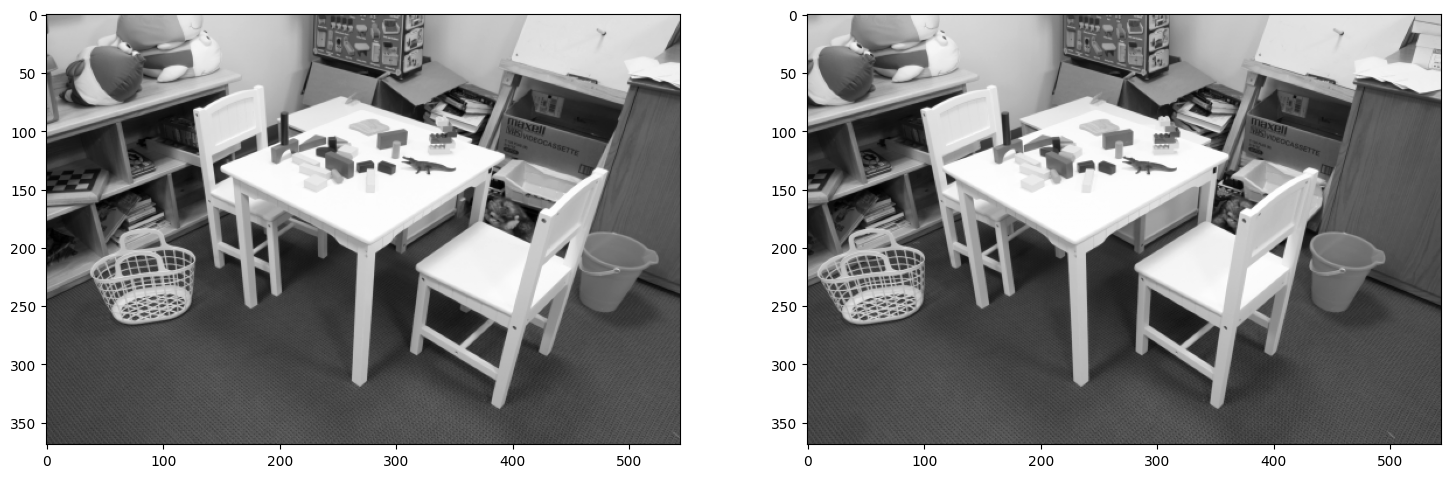

In [10]:
# Load a stereo image pair (two photos of the same scene taken from slightly
# different horizontal positions) and prepare them for block matching.
# Why resize: stereo block matching compares many small pixel blocks between
# the two images at many candidate offsets, which is computationally expensive.
# Working at 1/5 resolution here dramatically speeds this up while still
# producing a usable disparity map, which is why it's recommended especially
# while still experimenting with parameters.
# Why grayscale: cv2.StereoBM (used below) operates on single-channel
# intensity images, comparing brightness patterns between the left/right
# views rather than full color. It doesn't need color information to find
# matching blocks.
# Load the images.
img_left = cv2.imread("playtable_left.png")
img_right = cv2.imread("playtable_right.png")

# Rescale images (can be left out).
img_size = (int(img_left.shape[1]/5), int(img_left.shape[0]/5))
img_left = cv2.resize(img_left, img_size, interpolation=cv2.INTER_AREA)
img_right = cv2.resize(img_right, img_size, interpolation=cv2.INTER_AREA)

# Convert images to grayscale for template matching.
gray_left = cv2.cvtColor(img_left, cv2.COLOR_BGR2GRAY)
gray_right = cv2.cvtColor(img_right, cv2.COLOR_BGR2GRAY)

f, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(18,18))
ax_left.imshow(gray_left)
ax_right.imshow(gray_right)

Next step is to create a disparity map based on the two stereo images. This is done using the same procedure as we did with exercise 1, except now we look for blocks of pixel from the left image in the right image, or vice versa.

## Exercise 2.1
You will have to play with the below parameters until you find a good solution that gives a representative 3D projection. Reflect/search on what those parameters actually mean and how they influence the outcome.

246 68.0


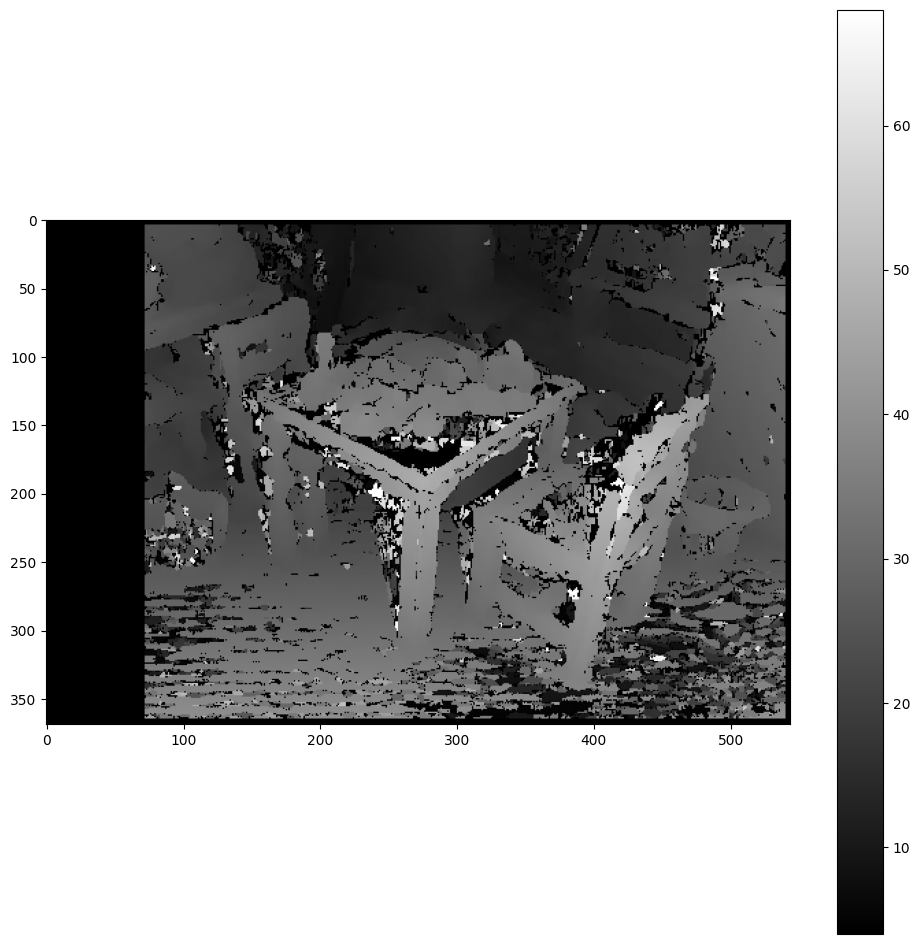

In [11]:
# Why disparity maps: for a stereo image pair, the same real-world point appears
# at a different horizontal pixel position in each image. This shift
# ("disparity") is inversely related to the point's distance from the camera
# (nearby objects shift more, far-away objects shift less). Computing disparity
# for every pixel therefore gives us a rough measure of depth across the whole
# scene.
#   - cv2.StereoBM_create(numDisparities, blockSize): the core matcher.
#     For each block of pixels in the left image, it searches for the
#     most similar block along the same row in the right image (stereo
#     images only need a horizontal search since a well-aligned pair only
#     differs by horizontal shift, not vertical).
#       numDisparities (num_disp): the range of pixel-shift values to
#         search over; must be a positive multiple of 16. A larger range
#         lets the algorithm detect larger disparities (i.e. closer
#         objects), but at higher computational cost.
#       blockSize (block_size): the size of the square pixel block
#         compared between images; must be odd. Larger blocks give
#         smoother, less noisy disparity maps but blur out fine detail
#         and thin structures; smaller blocks preserve detail but are
#         noisier.
#   - setMinDisparity(min_disp): the smallest disparity value considered
#     valid. Effectively sets how far away the closest expected object
#     can be, shifting the search window.
#   - setDisp12MaxDiff(200): a consistency-check threshold (left-right
#     disparity check). Kept very permissive (200) here, meaning this
#     particular consistency filter is effectively not rejecting matches.
#   - setUniquenessRatio(1): how much better the best match must be than
#     the next-best candidate match to be accepted, as a percentage. A very low
#     (1) means the algorithm is quite lenient about accepting a "best guess"
#     match even when it's not much better than the second-best option.
#   - setSpeckleRange / setSpeckleWindowSize: control post-processing that
#     removes small, isolated "speckle" regions of noise from the disparity map.
#     speckleWindowSize sets the size of the area checked for small isolated
#     regions, and speckleRange sets how much disparity variation within that
#     region is tolerated before it's considered noise and cleared out.
#   - stereo.compute(gray_left, gray_right) returns a disparity map scaled
#     internally by 16x (a StereoBM implementation detail, to preserve sub-pixel
#     precision using integer output), so we divide by 16.0 (after casting to
#     float32) to get back real disparity values in pixels.
# The result is visualized as a heatmap with a colorbar, and we print the max
# grayscale intensity alongside the max disparity value found.
min_disp = 5
num_disp = 4 * 16
block_size = 9
stereo = cv2.StereoBM_create(numDisparities = num_disp, blockSize = block_size)
stereo.setMinDisparity(min_disp)
stereo.setDisp12MaxDiff(200)
stereo.setUniquenessRatio(1)
stereo.setSpeckleRange(3)
stereo.setSpeckleWindowSize(3)
disp = stereo.compute(gray_left, gray_right).astype(np.float32) / 16.0

plt.figure(figsize=(12,12))
plt.imshow(disp)
plt.colorbar()
print(gray_left.max(), disp.max())

## Exercise 2.2
Once you have a disparity map without too much noise, you can use the below to export you disparity map to a .ply file that you can load and display in a 3D visualization software (e.g. [Meshlab](https://www.meshlab.net/#description)).

**Hint:** To open meshlab type `meshlab` in a terminal. 
To vizualize the point cloud, drag the generated `out.ply` into the meshlab scene or click `File` > `Import Mesh` and navigate to where our source-code is located and open `out.ply`. 

In [ ]:
# A disparity map alone is just a 2D image of "how far things shifted". To get
# an actual 3D point cloud (an (x, y, z) coordinate per pixel, with color), we
# need to reproject each pixel's disparity value into 3D space using camera
# geometry.
#   - The 'Q' matrix here is a simplified/approximate reprojection matrix
#     (normally this would come from a proper stereo camera calibration), built
#     manually using a rough guess for the focal length ('f') based on image
#     width, and hand-placed values to re-center the coordinate origin and flip
#     the axes into a more intuitive orientation (y pointing up, matching
#     typical 3D viewer conventions, instead of image row-coordinates which
#     increase downward).
#   - cv2.reprojectImageTo3D(disparity_map, Q) uses this matrix to convert each
#     pixel + its disparity value into a corresponding 3D (x, y, z) point.
#   - mask = disparity_map > disparity_map.min() filters out pixels where block
#     matching failed to find any valid disparity (which StereoBM marks using
#     the minimum possible value). These would otherwise produce meaningless or
#     invalid 3D points.
#   - 'out_points'/'out_colors' keep only the valid, masked points and their
#     corresponding original-image colors.
#   - write_ply() manually constructs a minimal .ply file: it writes a text
#     header describing the vertex count and per-vertex properties (3D position
#     + RGB color), then writes each point's data as a row of space-separated
#     values using np.savetxt().
# The two print() calls are quick debug checks comparing the raw minimum
# disparity value against the minimum disparity found only within the masked
# (valid) region, to confirm the masking behaved as expected.
def export_pointcloud(disparity_map, colors):
    ply_header = '''ply
    format ascii 1.0
    element vertex %(vert_num)d
    property float x
    property float y
    property float z
    property uchar red
    property uchar green
    property uchar blue
    end_header
    '''

    def write_ply(fn, verts, colors):
        verts = verts.reshape(-1, 3)
        colors = colors.reshape(-1, 3)
        verts = np.hstack([verts, colors])
        with open(fn, 'wb') as f:
            f.write((ply_header % dict(vert_num=len(verts))).encode('utf-8'))
            np.savetxt(f, verts, fmt='%f %f %f %d %d %d ')

    h, w = disparity_map.shape[:2]
    # Guess for focal length. If you 3D reconstruction looks skewed in the
    # viewing direction, try adjusting this parameter.
    f = .8 * w
    Q = np.float32([[1, 0, 0, -0.5 * w],
                    [0, -1, 0, 0.5 * h],  # turn points 180 deg around x-axis,
                    [0, 0, 0, -f],  # so that y-axis looks up
                    [0, 0, 1, 0]])
    points = cv2.reprojectImageTo3D(disparity_map, Q)

    mask = disparity_map > disparity_map.min()

    print(disparity_map.min())
    print(disparity_map[mask].min())

    out_points = points[mask]
    out_colors = colors[mask]
    out_fn = 'out.ply'
    write_ply('out.ply', out_points, out_colors)
    print(f'{out_fn} saved')

export_pointcloud(disparity_map=disp, colors=cv2.resize(img_left, img_size, interpolation=cv2.INTER_AREA))

4.0
5.0
out.ply saved


## Exercise 2.3

Create a disparity map of the imageset `storage` and display it in meshlab.

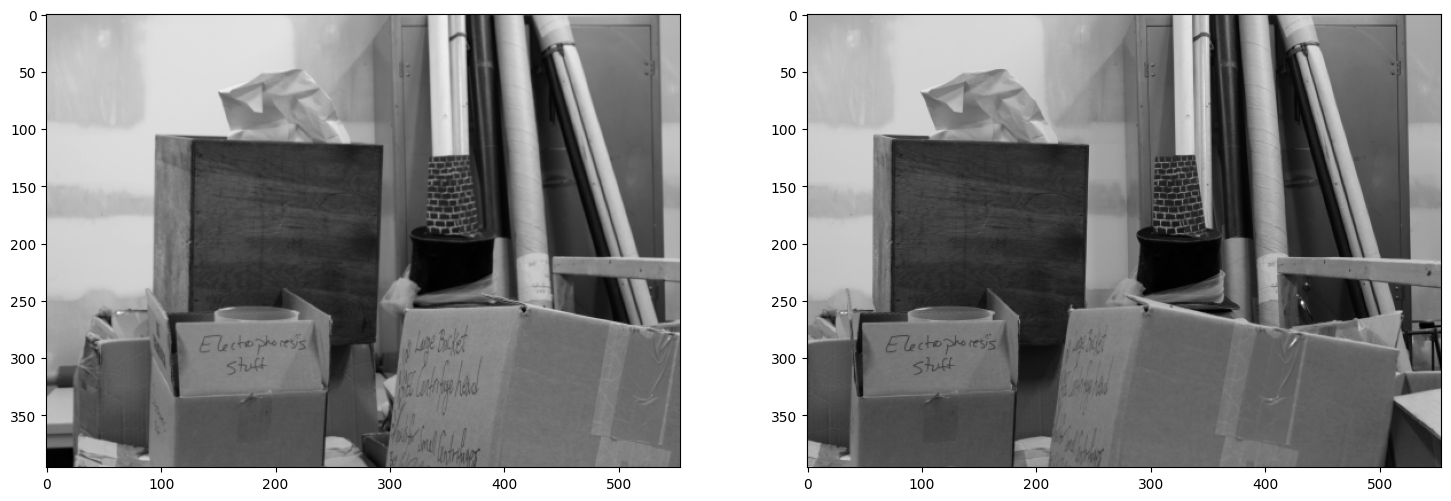

In [13]:
# Repeat the exact same loading/rescaling/grayscale pipeline as before, this
# time on a different stereo pair ("storage"), to test whether the same block-
# matching approach generalizes to a new scene.
# Load the images.
img_left = cv2.imread("storage_left.png")
img_right = cv2.imread("storage_right.png")

# Rescale images (can be left out).
img_size = (int(img_left.shape[1]/5), int(img_left.shape[0]/5))
img_left = cv2.resize(img_left, img_size, interpolation=cv2.INTER_AREA)
img_right = cv2.resize(img_right, img_size, interpolation=cv2.INTER_AREA)

# Convert images to grayscale for template matching.
gray_left = cv2.cvtColor(img_left, cv2.COLOR_BGR2GRAY)
gray_right = cv2.cvtColor(img_right, cv2.COLOR_BGR2GRAY)

f, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(18,18))
ax_left.imshow(gray_left)
ax_right.imshow(gray_right)

Max values: 246 Max disparity: 68.0
4.0
5.0
out.ply saved


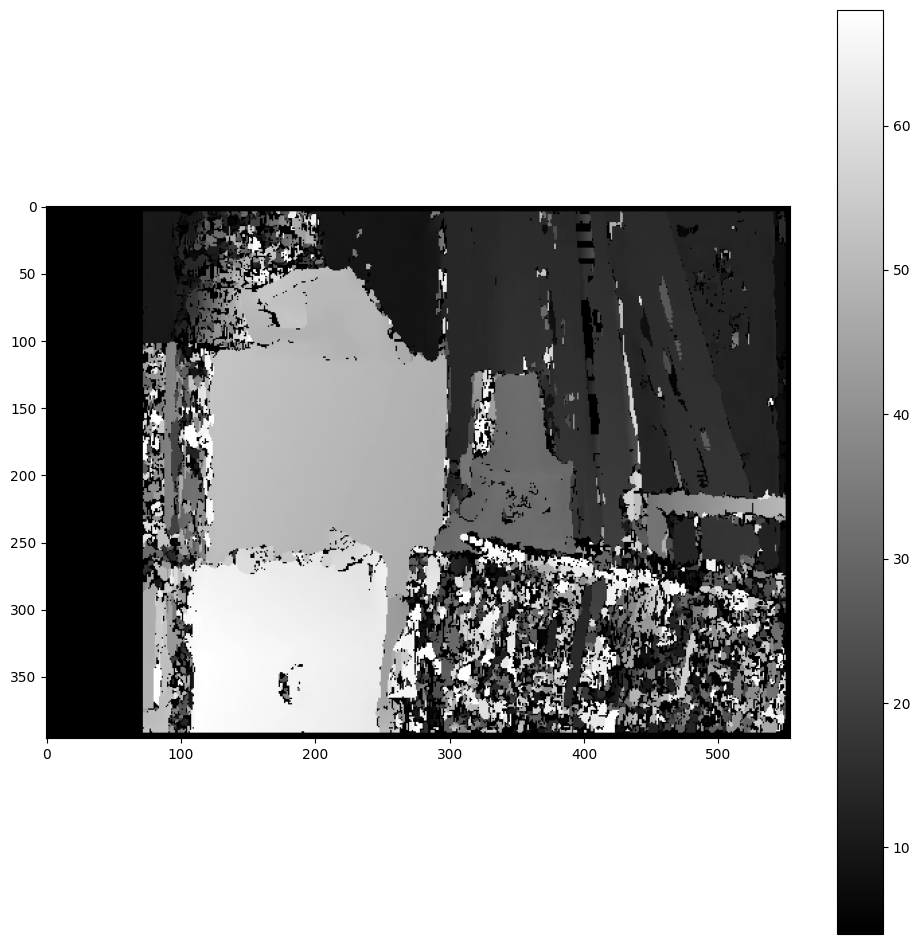

In [17]:
# Compute and visualize the disparity map for the "storage" stereo pair, using
# the exact same StereoBM parameters and steps as Exercise 2.1 above. Export the
# "storage" scene's disparity map as a 3D point cloud
min_disp = 5
num_disp = 4 * 16
block_size = 9
stereo = cv2.StereoBM_create(numDisparities = num_disp, blockSize = block_size)
stereo.setMinDisparity(min_disp)
stereo.setDisp12MaxDiff(200)
stereo.setUniquenessRatio(1)
stereo.setSpeckleRange(3)
stereo.setSpeckleWindowSize(3)
disp = stereo.compute(gray_left, gray_right).astype(np.float32) / 16.0

plt.figure(figsize=(12,12))
plt.imshow(disp)
plt.colorbar()
print("Max values:", gray_left.max(), "Max disparity:", disp.max())

export_pointcloud(disparity_map=disp, colors=cv2.resize(img_left, img_size, interpolation=cv2.INTER_AREA))